In [7]:
import torch
import numpy
from matplotlib import pyplot

import importlib
import velocity_model
import estimate_velocity
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

L = 5e6
Growthrate = torch.tensor([1/(20*60)], dtype=torch.double)
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
delay = torch.tensor([360.0, 0.0], dtype=torch.double)
h_tgrid = torch.linspace(0, 0.6*Tr, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

mtrue = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)
mtrue.growthrate = Growthrate
mtrue.delay = delay
mtrue.v0 = torch.tensor([v0], dtype=torch.double)
mtrue.h_log_raw = torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double))
mtrue.g_log = torch.log(torch.tensor([10, 2], dtype=torch.double))

coverage = 1e3
x = torch.linspace(0, L, steps=1000)
y_obs = torch.poisson(mtrue.P(x) * coverage).detach().numpy()
s_obs = numpy.sqrt(y_obs)

In [8]:
importlib.reload(velocity_model)
importlib.reload(estimate_velocity)

h_tgrid_dense = torch.linspace(0, Tr, steps=1000, dtype=torch.double)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid_dense, g_xranges_l, g_xranges_u)
m.growthrate = Growthrate
m.g_sigma = torch.tensor([10], dtype=torch.double)
m.h_sigma = torch.tensor([5], dtype=torch.double)
m.h_timescale = torch.tensor([250], dtype=torch.double)

#torch.autograd.set_detect_anomaly(True)
l = velocity_model.VelocityModelLoss(x, torch.tensor(y_obs), torch.tensor(s_obs), m)
fit = estimate_velocity.FitVelocityModel(m, l)
fit.optimize_parameters()

In [9]:
params = [m.v0_scaled, m.g_log, m.h_log_raw]
print(fit.evaluate_model_for_parameters(params))
print(m.pvector(params))
print(m.pgradient(params))

tensor([1.], dtype=torch.float64, grad_fn=<DivBackward0>)
tensor([ 8.1125e-01,  2.3227e+00,  6.7583e-01,  3.0759e-05, -1.3351e-04,
         1.2550e-04, -3.4188e-04, -6.7012e-04, -3.3281e-04,  1.1436e-03,
         1.7081e-03,  5.6829e-03,  5.7252e-03,  3.8726e-02,  1.0073e-01,
        -5.3702e-02,  1.3757e-01,  7.2127e-01,  3.2833e-01, -9.8920e-01,
        -4.9263e-01,  2.1639e-01,  2.4786e-01, -5.7063e-02, -6.6299e-03,
         2.9535e-01,  3.6987e-01, -7.8470e-03,  1.1674e-01,  2.5758e-01,
        -4.8495e-02,  1.3460e-02], dtype=torch.float64, grad_fn=<CopySlices>)
tensor([ 1.6531e-03,  2.9104e-04,  9.0182e-04, -6.5685e-08,  2.3029e-07,
        -1.4551e-07,  7.0074e-07,  1.8230e-06,  1.0722e-06, -4.3293e-06,
        -7.0024e-06, -9.5913e-06, -4.6843e-05, -1.2960e-04, -1.6378e-04,
         1.1039e-04,  2.3841e-04, -1.5385e-04,  5.4758e-06,  3.4626e-04,
        -7.4354e-05, -1.1812e-04,  4.2656e-04, -1.7760e-04, -1.4808e-04,
         6.6983e-05,  1.2084e-03, -2.5935e-03, -1.5230e-04,  

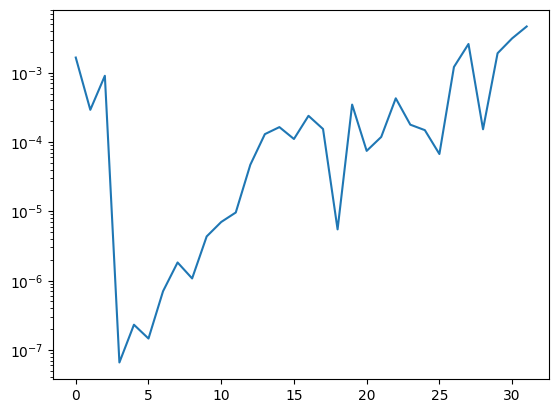

In [10]:
pyplot.plot(abs(m.pgradient(params)))
pyplot.yscale("log")

Text(0, 0.5, 'abundance [reads]')

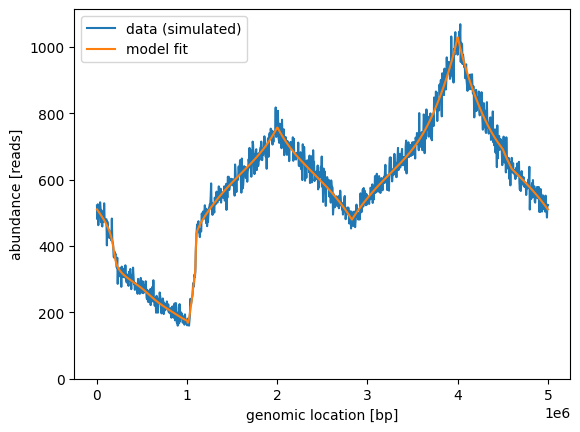

In [11]:
pyplot.plot(fit.loss.x, fit.loss.y_obs.detach(), label="data (simulated)")
pyplot.plot(fit.loss.x, fit.loss.y_pred().detach(), label="model fit")
pyplot.legend()
pyplot.ylim(ymin=0)
pyplot.xlabel("genomic location [bp]")
pyplot.ylabel("abundance [reads]")

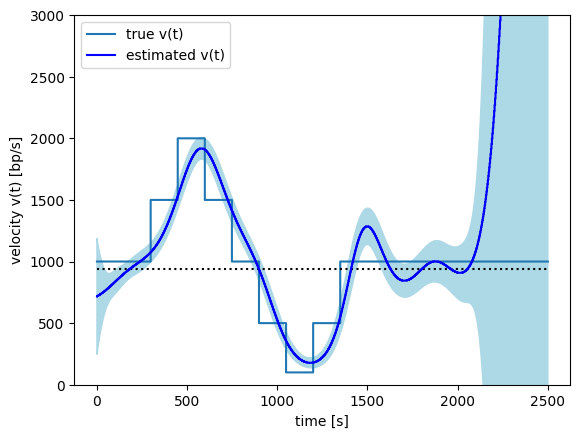

In [12]:
pyplot.step(h_tgrid_dense, mtrue.v_t(h_tgrid_dense).detach(), label="true v(t)")
p_cov, p_pmap = fit.parameter_posterior_cov()
i, l = p_pmap["h_log_raw"], torch.numel(m.h_log_raw)
v_t = m.v_t(fit.model.h_tgrid).detach()
v_t_stderr = m.v_t_posterior_stderr(fit.model.h_tgrid, p_cov, p_pmap).detach()
pyplot.hlines([m.v0.detach()], xmin=0, xmax=m.h_tgrid.max(),
              linestyle="dotted", color="black")
pyplot.step(h_tgrid_dense, v_t, label="estimated v(t)", color="blue")
pyplot.fill_between(h_tgrid_dense,  v_t - v_t_stderr, v_t + v_t_stderr, color="lightblue")
pyplot.xlabel("time [s]")
pyplot.ylabel("velocity v(t) [bp/s]")
pyplot.ylim([0, 3000])
pyplot.legend()